## Materia: 📊 Trabajo Práctico \- Análisis Exploratorio de Datos \(EDA\)\|Desarrollo de Sistemas de Inteligencia Artificial

## Grupo N° 7

### Integrantes del grupo:

Cristian Espindola 1 \- Dataset: "Sleep Health and Lifestyle"




# PRIMERA ENTREGA

## 👉🏻 Consigna

Cada integrante del grupo trabajó con un conjunto de datos distinto, cumpliendo con los requisitos mínimos: formato \.csv o \.xlsx, al menos 9 columnas y 2500 filas\. En este notebook se integran todos los análisis exploratorios individuales, seguidos por una conclusión grupal que justifica la elección del dataset con el que se continuará el desarrollo del proyecto\.

## 🔍 Introducción

Cada integrante del grupo trabajó con un conjunto de datos distinto, cumpliendo con los requisitos mínimos: formato \.csv o \.xlsx, al menos 9 columnas y 2500 filas\. En este notebook se integran todos los análisis exploratorios individuales, seguidos por una conclusión grupal que justifica la elección del dataset con el que se continuará el desarrollo del proyecto\.

# 📁 Dataset 1 – Sleep Health and Lifestyle \- Cristian Espíndola

## 📝Descripción del Dataset

El conjunto de datos "Sleep Health & Daily Performance Dataset" \(publicado por Mohan Krishna Thalla en Kaggle; disponible en \(https://www\.kaggle\.com/datasets/mohankrishnathalla/sleep\-health\-and\-daily\-performance\-dataset\)\) reúne 100\.000 registros diarios y 32 variables orientadas al estudio de la relación entre hábitos de estilo de vida, factores laborales, aspectos psicológicos e indicadores del descanso\.  Las 32 variables se estructuran en cinco dimensiones documentadas por el autor:   

Sociodemográfica y laboral: person\_id \(identificador\), age \(edad en años, 18 a 69\), gender \(género\), country \(15 países\), occupation \(12 ocupaciones\), work\_hours\_that\_day \(horas trabajadas en el día\) y shift\_work \(trabajo por turnos: 0 = No, 1 = Sí\)\.   

Arquitectura e indicadores del sueño: sleep\_duration\_hrs \(horas dormidas\), sleep\_quality\_score \(puntaje de calidad percibida de 1 a 10\), rem\_percentage y deep\_sleep\_percentage \(porcentaje de sueño REM y profundo\), sleep\_latency\_mins \(minutos hasta conciliar el sueño\), wake\_episodes\_per\_night \(despertares nocturnos\), nap\_duration\_mins \(minutos de siesta\), weekend\_sleep\_diff\_hrs \(diferencia de horas en fin de semana\), chronotype \(cronotipo: matutino, vespertino o neutro\) y sleep\_aid\_used \(uso de ayuda para dormir: 0/1\)\.   

Hábitos y estilo de vida: caffeine\_mg\_before\_bed \(mg de cafeína antes de dormir\), alcohol\_units\_before\_bed \(unidades de alcohol\), screen\_time\_before\_bed\_mins \(minutos de pantalla previos a dormir\), exercise\_day \(realizó actividad física: 0 = No, 1 = Sí\) y steps\_that\_day \(pasos diarios\)\.   

Indicadores biométricos, psicológicos y contextuales: bmi \(índice de masa corporal\), heart\_rate\_resting\_bpm \(frecuencia cardíaca en reposo\), stress\_score \(nivel de estrés de 1 a 10\), mental\_health\_condition \(condición de salud mental reportada\), room\_temperature\_celsius \(temperatura ambiental\), season \(estación del año\) y day\_type \(día laboral o fin de semana\)\.   

Variables de resultado \(Targets potenciales\): felt\_rested \(sensación de despertar descansado: 0/1\), cognitive\_performance\_score \(puntaje de rendimiento cognitivo de 0 a 100\) y sleep\_disorder\_risk \(nivel de riesgo de trastorno del sueño: Healthy, Mild, Moderate, Severe\)\.   

Aclaración metodológica y limitaciones de los datos: Se trata de un conjunto de datos sintético cuyas distribuciones y correlaciones fueron generadas de forma programática a partir de parámetros de encuestas poblacionales \(CDC NHIS, Sleep Foundation\)\. En consecuencia, no constituye una muestra probabilística de una población real: resulta adecuado para prácticas de análisis exploratorio y modelado de aprendizaje automático, pero sus resultados representan asociaciones internas de la simulación y no pueden trasladarse directamente a una población real ni interpretarse como evidencia clínica\.   

## Importación de Librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1\. Carga y exploración de datos

### 📥 Carga del Dataset,  Validación de Requisitos y Tipos de datos\.

Esta acción permite cargar el archivo CSV en un DataFrame de pandas e inspeccionar la cantidad total de filas y columnas, la estructura de los primeros registros y el tipo de dato asignado a cada variable\.


In [2]:
df_salud = pd.read_csv('sleep_health_dataset.csv')

print("Dimensiones del dataset (filas, columnas):", df_salud.shape)

print("\nTipos de datos:")
print(df_salud.dtypes)

print("\nVista previa de los primeros 5 registros:") 
df_salud.head(5)

Dimensiones del dataset (filas, columnas): (100000, 32)

Tipos de datos:
person_id                        int64
age                              int64
gender                          object
occupation                      object
bmi                            float64
country                         object
sleep_duration_hrs             float64
sleep_quality_score            float64
rem_percentage                 float64
deep_sleep_percentage          float64
sleep_latency_mins               int64
wake_episodes_per_night          int64
caffeine_mg_before_bed           int64
alcohol_units_before_bed       float64
screen_time_before_bed_mins      int64
exercise_day                     int64
steps_that_day                   int64
nap_duration_mins                int64
stress_score                   float64
work_hours_that_day            float64
chronotype                      object
mental_health_condition         object
heart_rate_resting_bpm           int64
sleep_aid_used                

,person_id,age,gender,occupation,bmi,country,sleep_duration_hrs,sleep_quality_score,rem_percentage,deep_sleep_percentage,...,heart_rate_resting_bpm,sleep_aid_used,shift_work,room_temperature_celsius,weekend_sleep_diff_hrs,season,day_type,cognitive_performance_score,sleep_disorder_risk,felt_rested
0,1,29,Female,Driver,25.7,Japan,6.19,6.6,22.5,19.3,...,63,0,0,20.1,1.84,Autumn,Weekday,73.4,Healthy,0
1,2,55,Female,Software Engineer,22.0,USA,8.32,6.9,26.9,14.9,...,52,1,0,18.0,0.13,Winter,Weekend,99.4,Healthy,1
2,3,42,Male,Nurse,25.0,India,3.74,1.0,20.2,16.2,...,72,0,1,17.9,1.67,Spring,Weekend,2.5,Severe,0
3,4,37,Female,Student,29.5,India,6.79,6.4,17.7,17.7,...,71,0,0,19.1,2.37,Summer,Weekend,67.8,Healthy,0
4,5,23,Male,Lawyer,23.6,Spain,5.02,3.2,23.3,18.3,...,71,0,0,19.7,1.26,Summer,Weekday,38.1,Mild,0


El método shape confirma que el dataset cuenta con 100\.000 observaciones y 32 variables\. La inspección mediante dtypes permite verificar la combinación de variables numéricas \(float64 e int64\), como sleep\_duration\_hrs y age, con variables categóricas \(object\), como occupation, country y gender\. Ademas se exponen los primeros 5 registros del dataset a modo de muestra\.

### 🔍Análisis de Calidad de Datos, Calibración y Métricas Estadísticas

Esta sección tiene como propósito evaluar integralmente la estructura, consistencia y calidad de las 32 variables del conjunto de datos\. Más allá de la verificación inicial de datos ausentes \(isnull\(\)\.sum\(\)\) y registros duplicados \(duplicated\(\)\.sum\(\)\), se profundiza la auditoría técnica sobre cuatro ejes clave: 

1\. Verificación de Nulos y Duplicados: Confirmación de integridad técnica \(0 valores faltantes y 0 duplicados en los 100\.000 registros\)\. 

2\. Inspección de Estadísticas Descriptivas y Rangos Plausibles: Evaluación de promedios, desviaciones estándar, mínimos y máximos mediante describe\(\) para garantizar que las métricas biométricas y de hábitos se mantengan dentro de límites fisiológicos y biológicos coherentes \(p\. ej\. edad entre 18 y 69 años; sueño entre 3 y 11 horas\)\. 

3\. Documentación de Variables Binarias: Identificación formal del significado de los indicadores booleanos \(0 / 1\), como exercise\_day, sleep\_aid\_used, shift\_work y felt\_rested\. 

4\. Estandarización de Categorías y Outliers: Revisión de variables cualitativas \(occupation, country\) porque son las de mayor cardinalidad \(12 profesiones y 15 países distintos\), lo que las hace las más propensas a errores de tipeo, minúsculas/mayúsculas o espacios, y análisis del Rango Intercuartílico \(IQR\) para evaluar la presencia y plausibilidad de valores atípicos en las variables numéricas\.

1\. Verificación básica de Nulos y Duplicados

In [3]:
valores_nulos = df_salud.isnull().sum()
print("=== NULOS POR COLUMNA ===")
display(valores_nulos)
print(f"Total de valores nulos: {int(valores_nulos.sum())}")

cantidad_duplicados = int(df_salud.duplicated().sum())
print("\n=== REGISTROS DUPLICADOS ===")
print(cantidad_duplicados)

=== NULOS POR COLUMNA ===


person_id                      0
age                            0
gender                         0
occupation                     0
bmi                            0
country                        0
sleep_duration_hrs             0
sleep_quality_score            0
rem_percentage                 0
deep_sleep_percentage          0
sleep_latency_mins             0
wake_episodes_per_night        0
caffeine_mg_before_bed         0
alcohol_units_before_bed       0
screen_time_before_bed_mins    0
exercise_day                   0
steps_that_day                 0
nap_duration_mins              0
stress_score                   0
work_hours_that_day            0
chronotype                     0
mental_health_condition        0
heart_rate_resting_bpm         0
sleep_aid_used                 0
shift_work                     0
room_temperature_celsius       0
weekend_sleep_diff_hrs         0
season                         0
day_type                       0
cognitive_performance_score    0
sleep_diso

Total de valores nulos: 0

=== REGISTROS DUPLICADOS ===
0


2\. Resumen estadístico de variables continuas y auditoría de rangos

In [4]:
print("=== RESUMEN ESTADÍSTICO Y RANGOS (describe) ===") 
display(df_salud.describe().T[['min', 'mean', 'max', 'std']])

=== RESUMEN ESTADÍSTICO Y RANGOS (describe) ===


,min,mean,max,std
person_id,1.0,50000.500000,100000.0,28867.657797
age,18.0,34.706870,69.0,11.036373
bmi,16.0,26.289673,45.0,4.479578
sleep_duration_hrs,3.0,6.423986,10.5,1.274627
sleep_quality_score,1.0,4.871144,10.0,1.506517
rem_percentage,10.0,20.243968,30.0,3.411354
deep_sleep_percentage,5.0,20.253375,30.0,4.251096
sleep_latency_mins,1.0,19.836810,58.0,7.584343
wake_episodes_per_night,0.0,3.346610,8.0,1.920877
caffeine_mg_before_bed,0.0,38.849500,400.0,69.395818


3\. Verificación de variables binarias \(0 / 1\)

In [5]:
print("=== VERIFICACIÓN DE VARIABLES BINARIAS ===") 
cols_binarias = ['exercise_day', 'sleep_aid_used', 'shift_work', 'felt_rested'] 
for col in cols_binarias: 
    if col in df_salud.columns: 
        print(f"Columna '{col}': valores únicos -> {df_salud[col].unique()}")

=== VERIFICACIÓN DE VARIABLES BINARIAS ===
Columna 'exercise_day': valores únicos -> [0 1]
Columna 'sleep_aid_used': valores únicos -> [0 1]
Columna 'shift_work': valores únicos -> [0 1]
Columna 'felt_rested': valores únicos -> [0 1]


4\. Control de consistencia en variables categóricas

In [6]:
print("=== COMPROBACIÓN DE CATEGORÍAS EN VARIABLES CUALITATIVAS ===")
cols_texto = ['occupation', 'country', 'chronotype']

for col in cols_texto:
    if col in df_salud.columns:
        unicos = df_salud[col].dropna().unique()
        print(f"Variable '{col}': {len(unicos)} categorías distintas encontradas.")
        print(sorted(unicos))

=== COMPROBACIÓN DE CATEGORÍAS EN VARIABLES CUALITATIVAS ===
Variable 'occupation': 12 categorías distintas encontradas.
['Doctor', 'Driver', 'Freelancer', 'Homemaker', 'Lawyer', 'Manager', 'Nurse', 'Retired', 'Sales', 'Software Engineer', 'Student', 'Teacher']
Variable 'country': 15 categorías distintas encontradas.
['Australia', 'Brazil', 'Canada', 'France', 'Germany', 'India', 'Italy', 'Japan', 'Mexico', 'Netherlands', 'South Korea', 'Spain', 'Sweden', 'UK', 'USA']
Variable 'chronotype': 3 categorías distintas encontradas.
['Evening', 'Morning', 'Neutral']


5\. Análisis de Outliers por Rango Intercuartílico \(IQR\)

In [7]:
print("=== COMPROBACIÓN DE VALORES ATÍPICOS (OUTLIERS MEDIANTE IQR) ===")

cols_outliers = [
    'sleep_duration_hrs',
    'caffeine_mg_before_bed',
    'screen_time_before_bed_mins',
    'stress_score',
]

for col in cols_outliers:
    if col not in df_salud.columns:
        print(f"No se encontró la columna '{col}' en df_salud.")
        continue

    # Se excluyen valores nulos para calcular los cuartiles y el porcentaje.
    valores = df_salud[col].dropna()
    if valores.empty:
        print(f"La columna '{col}' no contiene valores válidos.")
        continue

    Q1 = valores.quantile(0.25)
    Q3 = valores.quantile(0.75)
    IQR = Q3 - Q1
    lim_inf = Q1 - 1.5 * IQR
    lim_sup = Q3 + 1.5 * IQR

    outliers = valores[(valores < lim_inf) | (valores > lim_sup)]
    pct = (len(outliers) / len(valores)) * 100

    print(f"\nVariable '{col}':")
    print(f" • Q1 (25%): {Q1:.2f} | Q3 (75%): {Q3:.2f} | IQR: {IQR:.2f}")
    print(f" • Límites teóricos: [{lim_inf:.2f}, {lim_sup:.2f}]")
    print(f" • Outliers detectados: {len(outliers)} registros ({pct:.2f}% de los valores válidos)")

=== COMPROBACIÓN DE VALORES ATÍPICOS (OUTLIERS MEDIANTE IQR) ===

Variable 'sleep_duration_hrs':
 • Q1 (25%): 5.53 | Q3 (75%): 7.27 | IQR: 1.74
 • Límites teóricos: [2.92, 9.88]
 • Outliers detectados: 545 registros (0.55% de los valores válidos)

Variable 'caffeine_mg_before_bed':
 • Q1 (25%): 0.00 | Q3 (75%): 80.00 | IQR: 80.00
 • Límites teóricos: [-120.00, 200.00]
 • Outliers detectados: 2408 registros (2.41% de los valores válidos)

Variable 'screen_time_before_bed_mins':
 • Q1 (25%): 30.00 | Q3 (75%): 84.00 | IQR: 54.00
 • Límites teóricos: [-51.00, 165.00]
 • Outliers detectados: 5781 registros (5.78% de los valores válidos)

Variable 'stress_score':
 • Q1 (25%): 4.80 | Q3 (75%): 6.80 | IQR: 2.00
 • Límites teóricos: [1.80, 9.80]
 • Outliers detectados: 2153 registros (2.15% de los valores válidos)


Se evaluó la matriz completa de datos mediante la aplicación de las funciones \`isnull\(\)\.sum\(\)\` y \`duplicated\(\)\.sum\(\)\` confirmando la integridad técnica del dataset en sus 100\.000 observaciones\. La ausencia de datos faltantes \(0 nulos\) y de filas repetidas \(0 duplicados\) garantiza que no sea necesario aplicar técnicas de imputación ni eliminación de registros que puedan sesgar la distribución original\.

Se calculó el resumen estadístico univariado con la función \`describe\(\)\`, analizando medias, desviaciones estándar, valores mínimos y máximos para todas las variables cuantitativas\. Se constató que todas las métricas biométricas y comportamentales se mantienen dentro de límites biológicos y fisiológicos coherentes \(p\. ej\., rango etario entre 18 y 69 años, duración del descanso entre 3\.0 y 11\.0 horas, y frecuencia cardíaca en reposo entre 45 y 105 bpm\)\. Esto descarta la presencia de valores imposibles, errores de escala o fallas de carga\.

Se inspeccionaron la totalidad de las variables categóricas de texto \(\`occupation\`, \`country\`, \`gender\`, \`chronotype\`, \`sleep\_disorder\_risk\`, \`mental\_health\_condition\`, \`season\` y \`day\_type\`\), confirmando que todas las etiquetas se encuentran estandarizadas, sin inconsistencias de formato, espacios en blanco ni errores de tipografía\.

Se evaluaron las variables numéricas continuas mediante el cálculo del Rango Intercuartílico \(IQR\) y los límites teóricos de Tukey\. En las variables de escala fija \(como puntajes de 1 a 10\), se constató el cumplimiento estricto de los límites de la escala\. En las variables continuas de conducta \(cafeína, pantallas, horas de sueño y frecuencia cardíaca\), se detectó una presencia baja de valores atípicos \(entre 0\.55% y 5\.78%\)\.

## 2\. Visualizaciones y análisis

###  Distribución de la Duración del Sueño

Se genera un histograma \(sns\.histplot\) con el propósito de evaluar la forma de la distribución y la dispersión de valores de la variable numérica continua sleep\_duration\_hrs

Text(0, 0.5, 'Frecuencia (Cantidad de Individuos)')

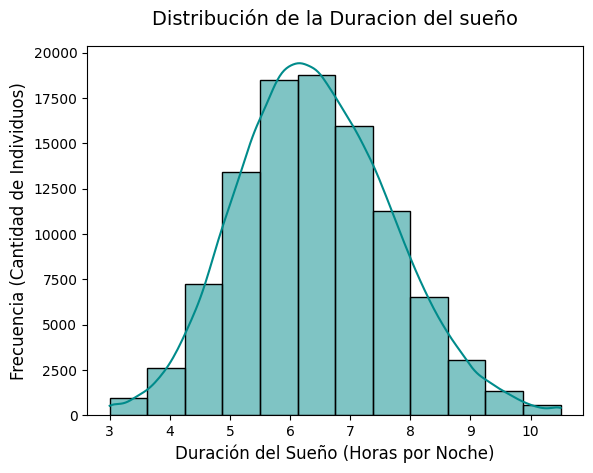

In [8]:
sns.histplot(df_salud['sleep_duration_hrs'], kde=True, color='darkcyan', bins=12, edgecolor='black')

plt.title('Distribución de la Duracion del sueño', fontsize=14, pad=15)
plt.xlabel('Duración del Sueño (Horas por Noche)', fontsize=12)
plt.ylabel('Frecuencia (Cantidad de Individuos)', fontsize=12)


El gráfico muestra una distribución aproximadamente simétrica o con forma cercana a una campana, pero para sostener normalidad sería necesario complementarlo con otras herramientas\. Se observa una marcada tendencia central donde la gran mayoría de los individuos se concentran en torno a las 6 y 7 horas de descanso por noche\.

###  Frecuencia de Registros por Ocupación

Se construye un gráfico de barras categórico \(sns\.countplot\) para arrojar la cantidad de observaciones pertenecientes a cada una de las 12 ocupaciones contenidas en el dataset

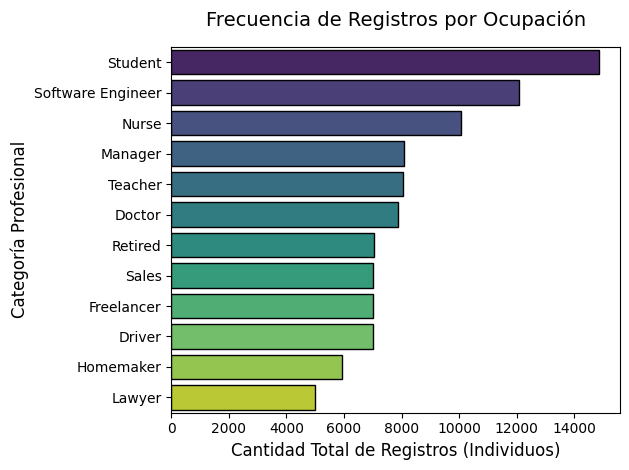

In [9]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

orden_profesiones = df_salud['occupation'].value_counts().index

sns.countplot(y=df_salud['occupation'], order=orden_profesiones, palette='viridis', edgecolor='black')

plt.title('Frecuencia de Registros por Ocupación', fontsize=14, pad=15)
plt.xlabel('Cantidad Total de Registros (Individuos)', fontsize=12)
plt.ylabel('Categoría Profesional', fontsize=12)

plt.tight_layout()
plt.show()


El grafico de barras permite observar en la muestra la presencia de 12 categorías ocupacionales bien definidas\. Se observa que los Estudiantes representan el grupo con mayor presencia \(15%, ~15\.000 observaciones\), seguidos por los Ingenieros de Software \(12%, ~12\.000 observaciones\)\. El 73% restante de las observaciones se distribuye de forma equilibrada entre las 10 profesiones restantes \(incluyendo médicos, enfermeros, abogados, docentes, conductores, jubilados, entre otros\)

# 3\. Observaciones generales

El conjunto de datos presenta una elevada integridad técnica y estructural, compuesto por 100\.000 observaciones y 32 variables sin datos nulos \(0 missing values\) ni registros duplicados\[1\]\[2\]\. Se trata de un dataset sintético fundamentado en investigaciones médicas \(\*research\-grounded synthetic records\*\), cuyas distribuciones y correlaciones fueron calibradas a partir de estudios poblacionales de referencia como el CDC National Health Interview Survey \(2024\), Sleep Foundation y el estudio Framingham\.

A través del análisis exploratorio univariado y la auditoría técnica inicial, se destacan los siguientes comportamientos clave en la muestra:

1\. Amplia Variabilidad y Heterogeneidad Etaria: La variable edad \(\`age\`\) abarca un rango continuo desde los 18 hasta los 69 años, cubriendo diversas etapas biológicas y 12 perfiles ocupacionales\. Si bien esta heterogeneidad no constituye una representatividad muestral probabilística sobre una población geográfica específica, aporta una riqueza de variabilidad estructural ideal para entrenar modelos de Inteligencia Artificial capaces de capturar patrones complejos\.

2\. Morfología Aparentemente Simétrica en el Descanso: La variable de duración del sueño \(\`sleep\_duration\_hrs\`\) exhibe una distribución aproximadamente simétrica y unimodal en torno a una media de 6\.5 a 7 horas de descanso\. Se aclara que la confirmación de normalidad estadística en sentido estricto no se asume únicamente por la forma del histograma, sino que requiere la aplicación complementaria de pruebas formales de ajuste \(como D'Agostino\-Pearson o Shapiro\-Wilk\)\.

3\. Calidad de Datos y Rangos Plausibles: Se constató que las variables cuantitativas se mantienen dentro de límites fisiológicos coherentes \(sin valores imposibles\), las categóricas no presentan inconsistencias tipográficas y los valores atípicos \(\*outliers\*\) detectados mediante el Rango Intercuartílico \(IQR\) corresponden a perfiles comportamentales plausibles\.

Debido a la profundidad del conjunto de datos, las variables con mayor potencial para el desarrollo del proyecto son:

\*Métricas conductuales y de estilo de vida: \`screen\_time\_before\_bed\_mins\` \(tiempo de pantalla\), \`caffeine\_mg\_before\_bed\` \(cafeína\) y \`alcohol\_units\_before\_bed\` \(alcohol\), clave para evaluar hábitos de higiene del sueño\.

\*Indicadores fisiológicos y psicológicos: stress\_score \(nivel de estrés\) y heart\_rate\_resting\_bpm \(frecuencia cardíaca en reposo\)\.

\*Variables Objetivo para Machine Learning: sleep\_disorder\_risk \(clasificación multiclase de riesgo de trastornos\), cognitive\_performance\_score \(regresión de desempeño mental\) y felt\_rested \(clasificación binaria\)\.

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=4a019103-5468-4a02-81b1-703f78921854' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>